# Experiment 4: Binary Classification using Linear and Kernel-Based Models

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import warnings
warnings.filterwarnings('ignore')

## 2. Load Dataset

In [2]:
df = pd.read_csv('spambase_csv.csv')
df.head()

,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_%3B,char_freq_%28,char_freq_%5B,char_freq_%21,char_freq_%24,char_freq_%23,capital_run_length_average,capital_run_length_longest,capital_run_length_total,class
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


## 3. Dataset Information

In [3]:
print('Shape:', df.shape)
print()
df.info()

Shape: (4601, 58)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4601 entries, 0 to 4600
Data columns (total 58 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   word_freq_make              4601 non-null   float64
 1   word_freq_address           4601 non-null   float64
 2   word_freq_all               4601 non-null   float64
 3   word_freq_3d                4601 non-null   float64
 4   word_freq_our               4601 non-null   float64
 5   word_freq_over              4601 non-null   float64
 6   word_freq_remove            4601 non-null   float64
 7   word_freq_internet          4601 non-null   float64
 8   word_freq_order             4601 non-null   float64
 9   word_freq_mail              4601 non-null   float64
 10  word_freq_receive           4601 non-null   float64
 11  word_freq_will              4601 non-null   float64
 12  word_freq_people            4601 non-null   float64
 13  word_freq_repo

In [ ]:
df.describe()

## 4. Missing Value Check

In [4]:
print('Missing values per column:')
print(df.isnull().sum())
print()
print('Total missing values:', df.isnull().sum().sum())
df.dropna(inplace=True)
df.drop_duplicates(inplace=True)
print('Shape after cleaning:', df.shape)

Missing values per column:
word_freq_make                0
word_freq_address             0
word_freq_all                 0
word_freq_3d                  0
word_freq_our                 0
word_freq_over                0
word_freq_remove              0
word_freq_internet            0
word_freq_order               0
word_freq_mail                0
word_freq_receive             0
word_freq_will                0
word_freq_people              0
word_freq_report              0
word_freq_addresses           0
word_freq_free                0
word_freq_business            0
word_freq_email               0
word_freq_you                 0
word_freq_credit              0
word_freq_your                0
word_freq_font                0
word_freq_000                 0
word_freq_money               0
word_freq_hp                  0
word_freq_hpl                 0
word_freq_george              0
word_freq_650                 0
word_freq_lab                 0
word_freq_labs                0
word_freq_tel

## 5. Exploratory Data Analysis

In [5]:
target_col = df.columns[-1]
print('Target column:', target_col)
print()
print('Class distribution:')
print(df[target_col].value_counts())

Target column: class

Class distribution:
class
0    2531
1    1679
Name: count, dtype: int64


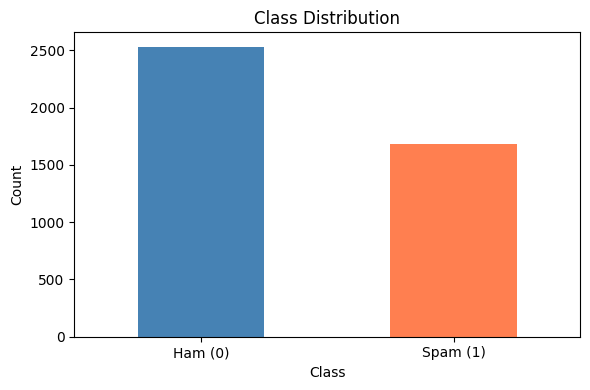

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
df[target_col].value_counts().plot(kind='bar', ax=ax, color=['steelblue', 'coral'])
ax.set_title('Class Distribution')
ax.set_xlabel('Class')
ax.set_ylabel('Count')
ax.set_xticklabels(['Ham (0)', 'Spam (1)'], rotation=0)
plt.tight_layout()
plt.show()

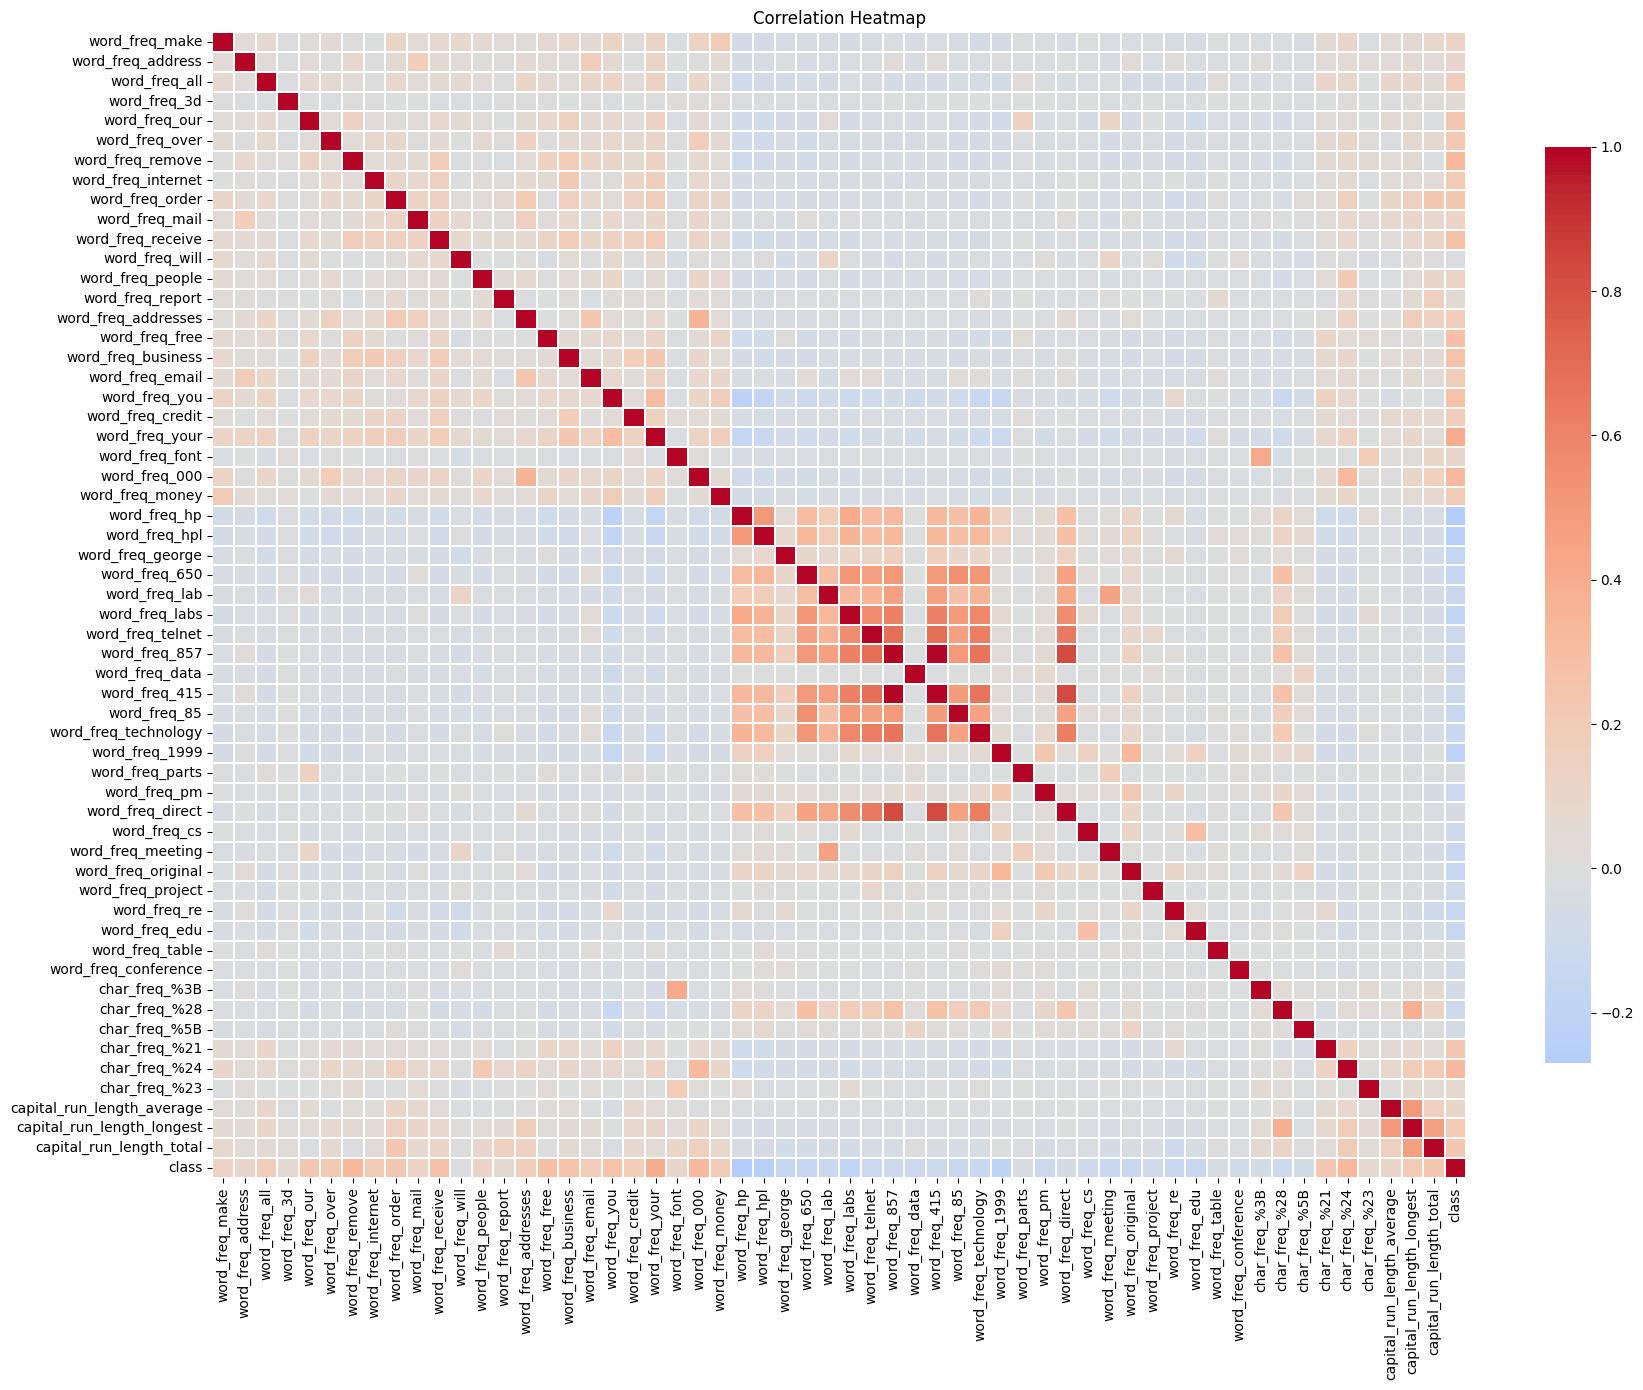

In [7]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
feature_cols = [c for c in numeric_cols if c != target_col]
corr_matrix = df[numeric_cols].corr()
plt.figure(figsize=(18, 14))
sns.heatmap(corr_matrix, cmap='coolwarm', center=0, linewidths=0.3, cbar_kws={'shrink': 0.8})
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

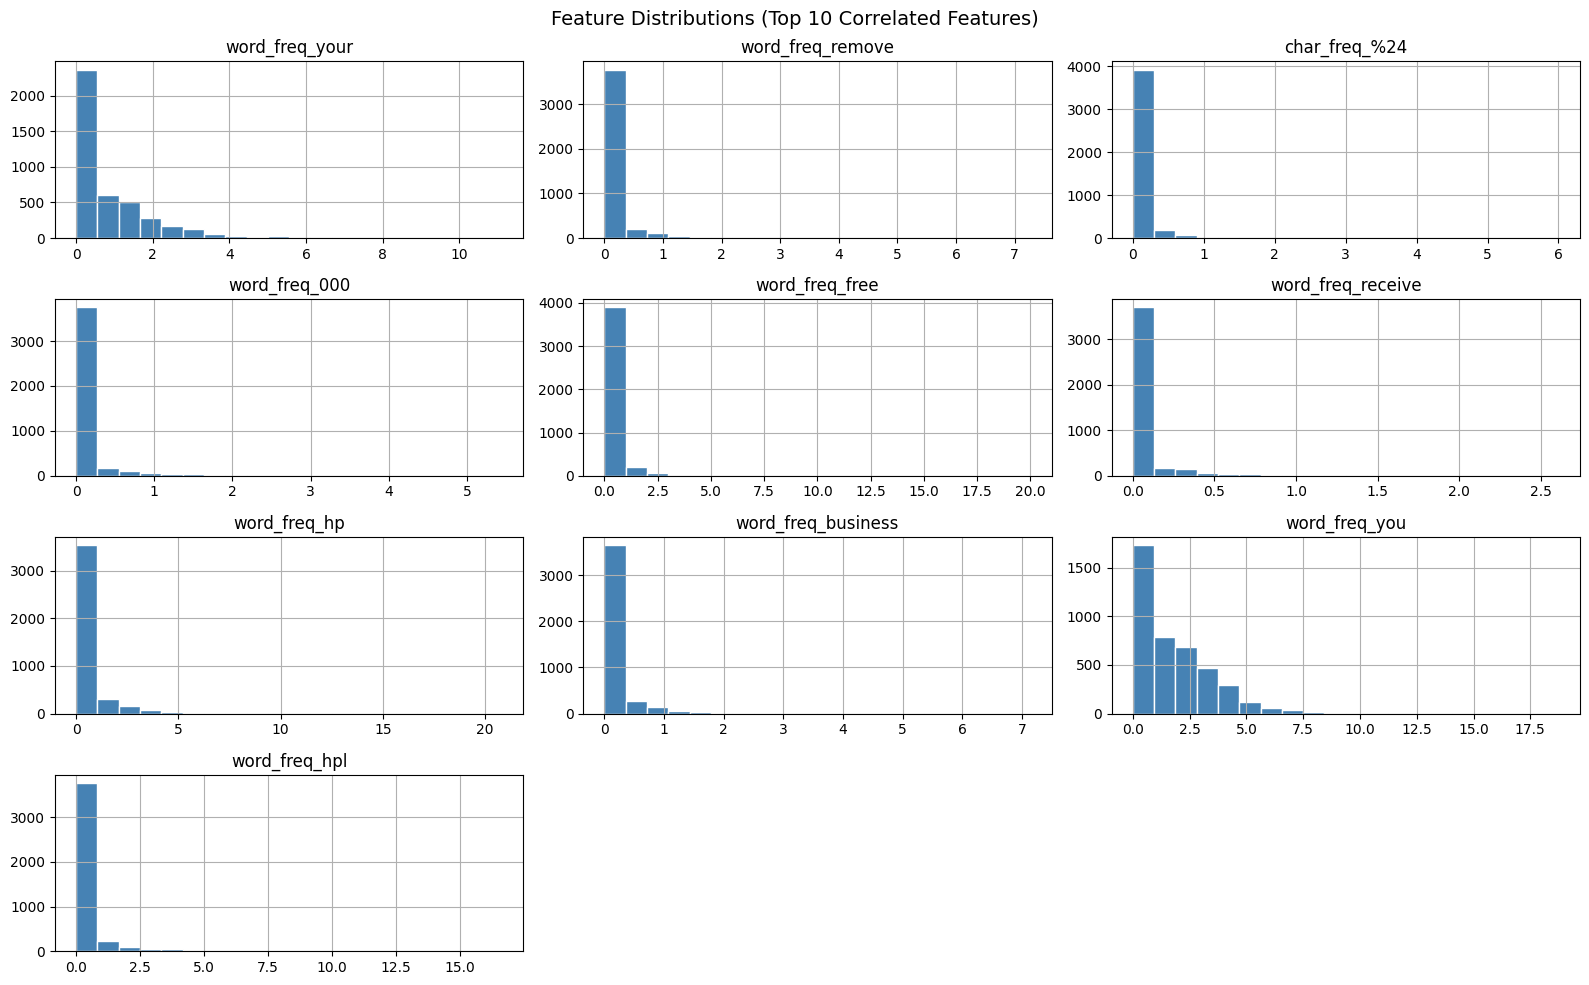

In [8]:
top_features = corr_matrix[target_col].abs().sort_values(ascending=False).iloc[1:11].index.tolist()
df[top_features].hist(bins=20, figsize=(16, 10), color='steelblue', edgecolor='white')
plt.suptitle('Feature Distributions (Top 10 Correlated Features)', fontsize=14)
plt.tight_layout()
plt.show()

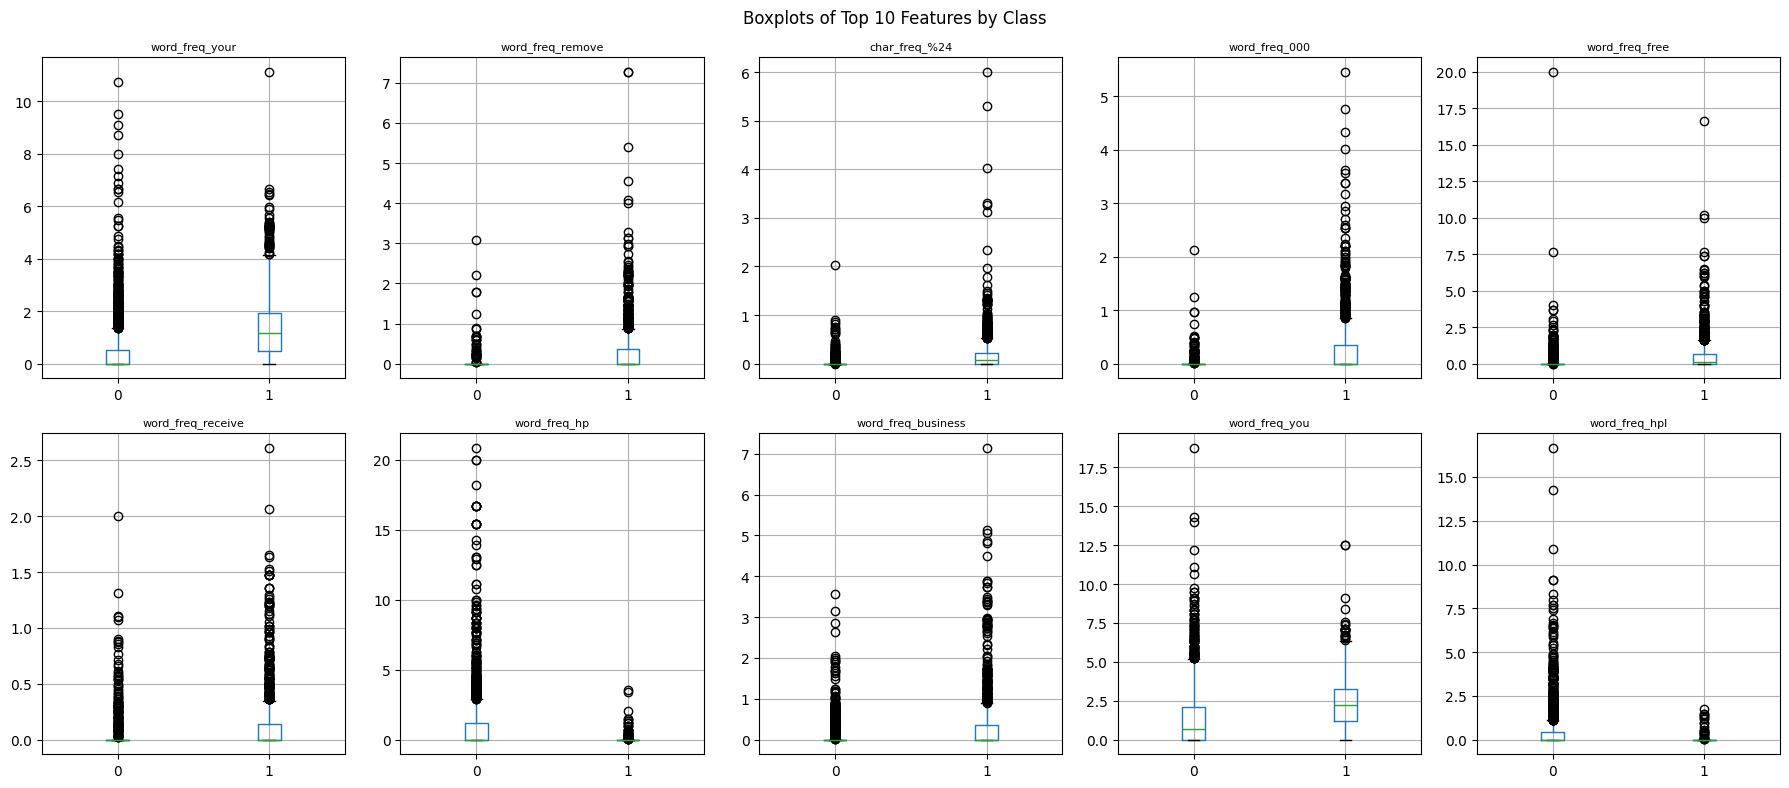

In [9]:
fig, axes = plt.subplots(2, 5, figsize=(18, 8))
for idx, col in enumerate(top_features):
    ax = axes[idx // 5][idx % 5]
    df.boxplot(column=col, by=target_col, ax=ax)
    ax.set_title(col, fontsize=8)
    ax.set_xlabel('')
plt.suptitle('Boxplots of Top 10 Features by Class')
plt.tight_layout()
plt.show()

## 6. Feature Scaling

In [10]:
X = df[feature_cols].values
y = df[target_col].values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## 7. Train-Test Split

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)
print('Training samples:', X_train.shape[0])
print('Testing samples:', X_test.shape[0])

Training samples: 3368
Testing samples: 842


## 8. Baseline Logistic Regression

In [12]:
lr_start = time.time()
lr_baseline = LogisticRegression(random_state=42, max_iter=1000)
lr_baseline.fit(X_train, y_train)
lr_train_time = time.time() - lr_start
lr_pred = lr_baseline.predict(X_test)

## 9. Logistic Regression Evaluation

In [13]:
lr_acc = accuracy_score(y_test, lr_pred)
lr_prec = precision_score(y_test, lr_pred)
lr_rec = recall_score(y_test, lr_pred)
lr_f1 = f1_score(y_test, lr_pred)

print('Baseline Logistic Regression Results')
print(f'Accuracy      : {lr_acc:.4f}')
print(f'Precision     : {lr_prec:.4f}')
print(f'Recall        : {lr_rec:.4f}')
print(f'F1 Score      : {lr_f1:.4f}')
print(f'Training Time : {lr_train_time:.4f}s')
print()
print(classification_report(y_test, lr_pred, target_names=['Ham', 'Spam']))

Baseline Logistic Regression Results
Accuracy      : 0.9145
Precision     : 0.9284
Recall        : 0.8663
F1 Score      : 0.8963
Training Time : 0.0468s

              precision    recall  f1-score   support

         Ham       0.91      0.95      0.93       483
        Spam       0.93      0.87      0.90       359

    accuracy                           0.91       842
   macro avg       0.92      0.91      0.91       842
weighted avg       0.92      0.91      0.91       842



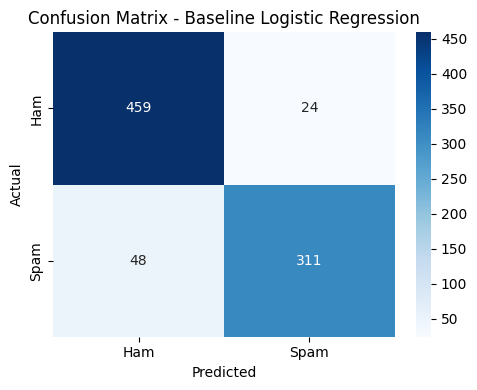

In [14]:
cm_lr = confusion_matrix(y_test, lr_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
plt.title('Confusion Matrix - Baseline Logistic Regression')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

## 10. Logistic Regression Hyperparameter Tuning

In [15]:
lr_param_grid = {
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear', 'saga'],
    'C': [0.01, 0.1, 1, 10, 100]
}
lr_grid = GridSearchCV(LogisticRegression(random_state=42, max_iter=2000), lr_param_grid, cv=5, scoring='accuracy', n_jobs=-1)
lr_grid.fit(X_train, y_train)
print('Best Parameters:', lr_grid.best_params_)
print('Best CV Score  :', round(lr_grid.best_score_, 4))

Best Parameters: {'C': 10, 'penalty': 'l2', 'solver': 'liblinear'}
Best CV Score  : 0.9228


## 11. Best Logistic Regression Evaluation

In [16]:
best_lr_start = time.time()
best_lr = lr_grid.best_estimator_
best_lr.fit(X_train, y_train)
best_lr_train_time = time.time() - best_lr_start
best_lr_pred = best_lr.predict(X_test)

best_lr_acc = accuracy_score(y_test, best_lr_pred)
best_lr_prec = precision_score(y_test, best_lr_pred)
best_lr_rec = recall_score(y_test, best_lr_pred)
best_lr_f1 = f1_score(y_test, best_lr_pred)

print('Best Logistic Regression Results')
print(f'Accuracy      : {best_lr_acc:.4f}')
print(f'Precision     : {best_lr_prec:.4f}')
print(f'Recall        : {best_lr_rec:.4f}')
print(f'F1 Score      : {best_lr_f1:.4f}')
print(f'Training Time : {best_lr_train_time:.4f}s')
print()
print(classification_report(y_test, best_lr_pred, target_names=['Ham', 'Spam']))

Best Logistic Regression Results
Accuracy      : 0.9216
Precision     : 0.9347
Recall        : 0.8774
F1 Score      : 0.9052
Training Time : 0.1088s

              precision    recall  f1-score   support

         Ham       0.91      0.95      0.93       483
        Spam       0.93      0.88      0.91       359

    accuracy                           0.92       842
   macro avg       0.92      0.92      0.92       842
weighted avg       0.92      0.92      0.92       842



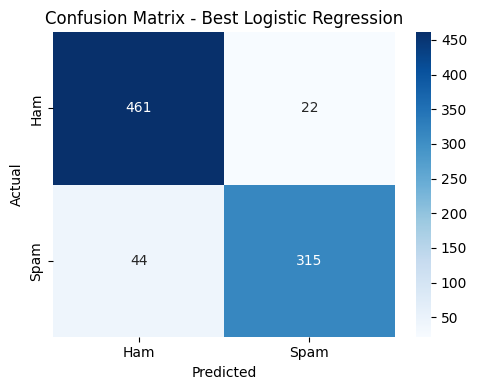

In [17]:
cm_best_lr = confusion_matrix(y_test, best_lr_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_best_lr, annot=True, fmt='d', cmap='Blues', xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
plt.title('Confusion Matrix - Best Logistic Regression')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

## 12. Baseline SVM

In [18]:
svm_baseline_start = time.time()
svm_baseline = SVC(random_state=42)
svm_baseline.fit(X_train, y_train)
svm_baseline_time = time.time() - svm_baseline_start
svm_baseline_pred = svm_baseline.predict(X_test)

print('Baseline SVM Results')
print(f'Accuracy      : {accuracy_score(y_test, svm_baseline_pred):.4f}')
print(f'F1 Score      : {f1_score(y_test, svm_baseline_pred):.4f}')
print(f'Training Time : {svm_baseline_time:.4f}s')

Baseline SVM Results
Accuracy      : 0.9145
F1 Score      : 0.8968
Training Time : 0.4759s


## 13. Train Separate SVM Models

In [19]:
kernels = ['linear', 'poly', 'rbf', 'sigmoid']
kernel_results = []

for kernel in kernels:
    start = time.time()
    model = SVC(kernel=kernel, random_state=42)
    model.fit(X_train, y_train)
    elapsed = time.time() - start
    pred = model.predict(X_test)
    kernel_results.append({
        'Kernel': kernel.capitalize(),
        'Accuracy': round(accuracy_score(y_test, pred), 4),
        'F1 Score': round(f1_score(y_test, pred), 4),
        'Training Time (s)': round(elapsed, 4)
    })
    print(f'Kernel: {kernel:10s} | Accuracy: {accuracy_score(y_test, pred):.4f} | F1: {f1_score(y_test, pred):.4f} | Time: {elapsed:.4f}s')

Kernel: linear     | Accuracy: 0.9228 | F1: 0.9075 | Time: 0.6096s
Kernel: poly       | Accuracy: 0.7553 | F1: 0.6128 | Time: 0.5639s
Kernel: rbf        | Accuracy: 0.9145 | F1: 0.8968 | Time: 0.2861s
Kernel: sigmoid    | Accuracy: 0.8789 | F1: 0.8555 | Time: 0.3068s


## 14. Compare Kernel Performance

In [20]:
kernel_df = pd.DataFrame(kernel_results)
print(kernel_df.to_string(index=False))

 Kernel  Accuracy  F1 Score  Training Time (s)
 Linear    0.9228    0.9075             0.6096
   Poly    0.7553    0.6128             0.5639
    Rbf    0.9145    0.8968             0.2861
Sigmoid    0.8789    0.8555             0.3068


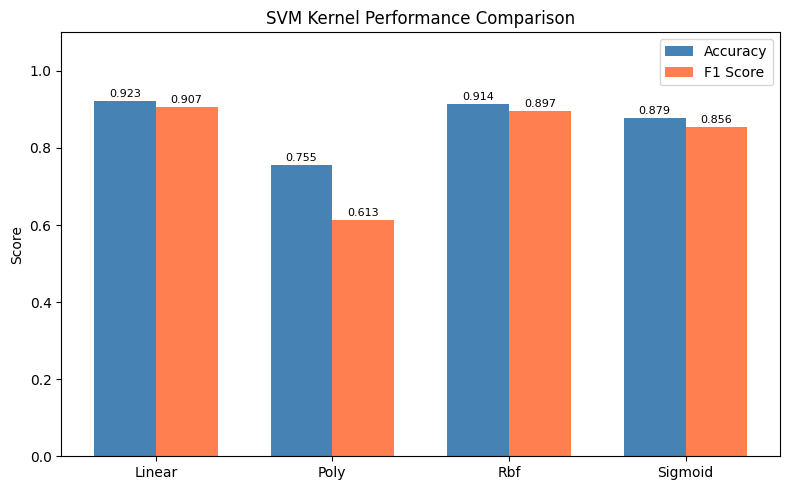

In [21]:
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(kernel_df))
width = 0.35
bars1 = ax.bar(x - width/2, kernel_df['Accuracy'], width, label='Accuracy', color='steelblue')
bars2 = ax.bar(x + width/2, kernel_df['F1 Score'], width, label='F1 Score', color='coral')
ax.set_xticks(x)
ax.set_xticklabels(kernel_df['Kernel'])
ax.set_ylim(0, 1.1)
ax.set_title('SVM Kernel Performance Comparison')
ax.set_ylabel('Score')
ax.legend()
for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f'{bar.get_height():.3f}', ha='center', fontsize=8)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f'{bar.get_height():.3f}', ha='center', fontsize=8)
plt.tight_layout()
plt.show()

## 15. Hyperparameter Tuning for SVM

In [22]:
svm_param_grid = {
    'kernel': ['linear', 'poly', 'rbf', 'sigmoid'],
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 'auto'],
    'degree': [2, 3, 4]
}
svm_grid = GridSearchCV(SVC(random_state=42), svm_param_grid, cv=5, scoring='accuracy', n_jobs=-1)
svm_grid.fit(X_train, y_train)
print('Best Parameters:', svm_grid.best_params_)
print('Best CV Score  :', round(svm_grid.best_score_, 4))

Best Parameters: {'C': 10, 'degree': 2, 'gamma': 'scale', 'kernel': 'rbf'}
Best CV Score  : 0.9299


## 16. Best SVM Evaluation

In [23]:
best_svm_start = time.time()
best_svm = svm_grid.best_estimator_
best_svm.fit(X_train, y_train)
best_svm_train_time = time.time() - best_svm_start
best_svm_pred = best_svm.predict(X_test)

best_svm_acc = accuracy_score(y_test, best_svm_pred)
best_svm_prec = precision_score(y_test, best_svm_pred)
best_svm_rec = recall_score(y_test, best_svm_pred)
best_svm_f1 = f1_score(y_test, best_svm_pred)

print('Best SVM Results')
print(f'Accuracy      : {best_svm_acc:.4f}')
print(f'Precision     : {best_svm_prec:.4f}')
print(f'Recall        : {best_svm_rec:.4f}')
print(f'F1 Score      : {best_svm_f1:.4f}')
print(f'Training Time : {best_svm_train_time:.4f}s')
print()
print(classification_report(y_test, best_svm_pred, target_names=['Ham', 'Spam']))

Best SVM Results
Accuracy      : 0.9133
Precision     : 0.9231
Recall        : 0.8691
F1 Score      : 0.8953
Training Time : 0.4425s

              precision    recall  f1-score   support

         Ham       0.91      0.95      0.93       483
        Spam       0.92      0.87      0.90       359

    accuracy                           0.91       842
   macro avg       0.91      0.91      0.91       842
weighted avg       0.91      0.91      0.91       842



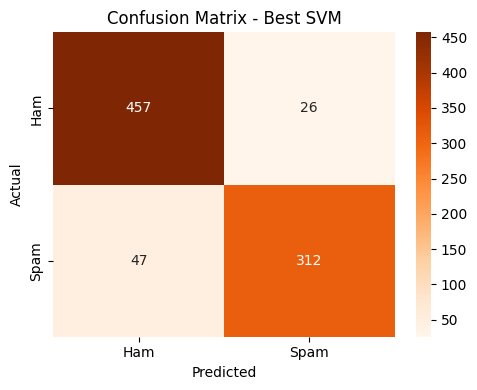

In [24]:
cm_best_svm = confusion_matrix(y_test, best_svm_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_best_svm, annot=True, fmt='d', cmap='Oranges', xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
plt.title('Confusion Matrix - Best SVM')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

## 17. 5-Fold Cross Validation

In [25]:
lr_cv_scores = cross_val_score(best_lr, X_scaled, y, cv=5, scoring='accuracy')
svm_cv_scores = cross_val_score(best_svm, X_scaled, y, cv=5, scoring='accuracy')

cv_df = pd.DataFrame({
    'Fold': [f'Fold {i+1}' for i in range(5)],
    'Logistic Regression': np.round(lr_cv_scores, 4),
    'SVM': np.round(svm_cv_scores, 4)
})
avg_row = pd.DataFrame([{
    'Fold': 'Average',
    'Logistic Regression': round(lr_cv_scores.mean(), 4),
    'SVM': round(svm_cv_scores.mean(), 4)
}])
cv_df = pd.concat([cv_df, avg_row], ignore_index=True)
print(cv_df.to_string(index=False))

   Fold  Logistic Regression    SVM
 Fold 1               0.9192 0.9359
 Fold 2               0.9252 0.9192
 Fold 3               0.9276 0.9442
 Fold 4               0.9394 0.9347
 Fold 5               0.8361 0.8468
Average               0.9095 0.9162


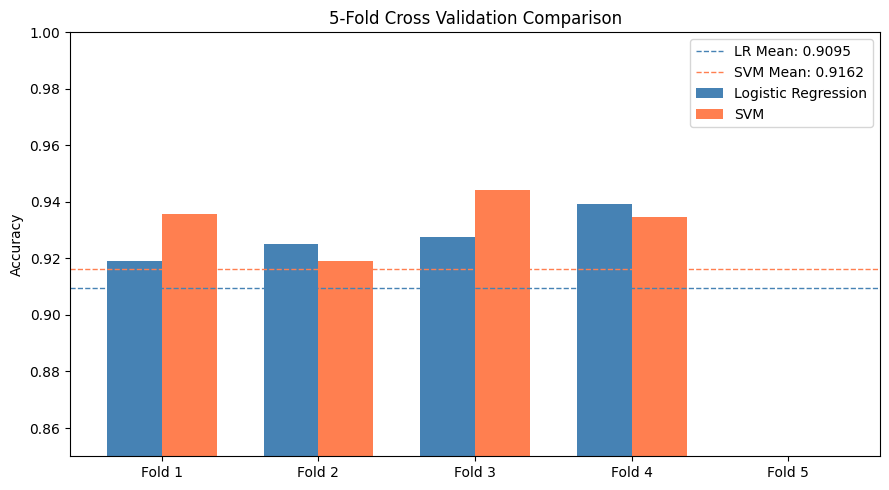

In [26]:
fold_labels = [f'Fold {i+1}' for i in range(5)]
x = np.arange(5)
width = 0.35
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x - width/2, lr_cv_scores, width, label='Logistic Regression', color='steelblue')
ax.bar(x + width/2, svm_cv_scores, width, label='SVM', color='coral')
ax.axhline(lr_cv_scores.mean(), color='steelblue', linestyle='--', linewidth=1, label=f'LR Mean: {lr_cv_scores.mean():.4f}')
ax.axhline(svm_cv_scores.mean(), color='coral', linestyle='--', linewidth=1, label=f'SVM Mean: {svm_cv_scores.mean():.4f}')
ax.set_xticks(x)
ax.set_xticklabels(fold_labels)
ax.set_ylim(0.85, 1.0)
ax.set_title('5-Fold Cross Validation Comparison')
ax.set_ylabel('Accuracy')
ax.legend()
plt.tight_layout()
plt.show()

## 18. Final Comparison

In [27]:
final_df = pd.DataFrame([
    {
        'Model': 'Logistic Regression (Baseline)',
        'Accuracy': round(lr_acc, 4),
        'Precision': round(lr_prec, 4),
        'Recall': round(lr_rec, 4),
        'F1 Score': round(lr_f1, 4),
        'Training Time (s)': round(lr_train_time, 4)
    },
    {
        'Model': 'Logistic Regression (Tuned)',
        'Accuracy': round(best_lr_acc, 4),
        'Precision': round(best_lr_prec, 4),
        'Recall': round(best_lr_rec, 4),
        'F1 Score': round(best_lr_f1, 4),
        'Training Time (s)': round(best_lr_train_time, 4)
    },
    {
        'Model': 'SVM (Baseline)',
        'Accuracy': round(accuracy_score(y_test, svm_baseline_pred), 4),
        'Precision': round(precision_score(y_test, svm_baseline_pred), 4),
        'Recall': round(recall_score(y_test, svm_baseline_pred), 4),
        'F1 Score': round(f1_score(y_test, svm_baseline_pred), 4),
        'Training Time (s)': round(svm_baseline_time, 4)
    },
    {
        'Model': 'SVM (Tuned)',
        'Accuracy': round(best_svm_acc, 4),
        'Precision': round(best_svm_prec, 4),
        'Recall': round(best_svm_rec, 4),
        'F1 Score': round(best_svm_f1, 4),
        'Training Time (s)': round(best_svm_train_time, 4)
    }
])
print(final_df.to_string(index=False))

                         Model  Accuracy  Precision  Recall  F1 Score  Training Time (s)
Logistic Regression (Baseline)    0.9145     0.9284  0.8663    0.8963             0.0468
   Logistic Regression (Tuned)    0.9216     0.9347  0.8774    0.9052             0.1088
                SVM (Baseline)    0.9145     0.9233  0.8719    0.8968             0.4759
                   SVM (Tuned)    0.9133     0.9231  0.8691    0.8953             0.4425


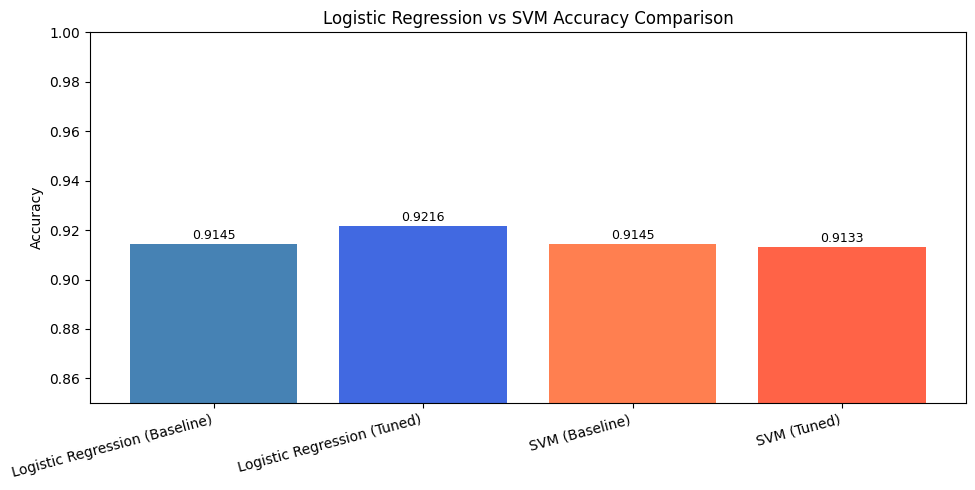

In [28]:
models = final_df['Model']
accuracies = final_df['Accuracy']
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(models, accuracies, color=['steelblue', 'royalblue', 'coral', 'tomato'])
ax.set_ylim(0.85, 1.0)
ax.set_title('Logistic Regression vs SVM Accuracy Comparison')
ax.set_ylabel('Accuracy')
ax.set_xticklabels(models, rotation=15, ha='right')
for bar in bars:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002, f'{bar.get_height():.4f}', ha='center', fontsize=9)
plt.tight_layout()
plt.show()


best_model_row = final_df.loc[final_df['Accuracy'].idxmax()]
best_model_name = best_model_row['Model']
best_model_acc = best_model_row['Accuracy']

lr_improvement = round(best_lr_acc - lr_acc, 4)
svm_improvement = round(best_svm_acc - accuracy_score(y_test, svm_baseline_pred), 4)
best_kernel_row = kernel_df.loc[kernel_df['Accuracy'].idxmax()]